# GHZ State — Qiskit Implementation

**Primitive:** 3-qubit GHZ state preparation, |GHZ> = (|000> + |111>) / sqrt(2)

**SETUP (assumed defaults)**
- N QUBITS: 3
- GATES (shared source of truth, used for circuit build AND diagram):
  1. H on qubit 0
  2. CX, control = qubit 0, target = qubit 1
  3. CX, control = qubit 1, target = qubit 2
- QUBIT ORDERING CONTRACT: qubit 0 = rightmost bit in every printed bitstring
- SHOTS: 10000, SEED: 42
- GLOBAL PHASE: normalized so first nonzero amplitude (ascending bitstring order) is real and positive

**Theory recap:** The GHZ state generalizes the Bell state to three (or more)
qubits: all qubits are either all |0> or all |1>, in equal superposition --
(|000> + |111>) / sqrt(2). It's built the same way a Bell state is, then
extended: H on qubit 0 creates the superposition, and a chain of CNOTs
(qubit i controls qubit i+1) propagates that superposition outward so every
qubit ends up correlated with qubit 0. Unlike the Bell state's single CX,
this is a **chain** of entangling gates -- CX(0,1) then CX(1,2) -- which is
the part most likely to introduce an off-by-one qubit-index bug if rushed,
so every gate below is built from the same explicit GATES list used for the
diagram, rather than re-typed by hand in multiple places.

H = 1/sqrt(2) * [[1, 1], [1, -1]]

CX(control, target): flips target iff control = 1.

**Bit-ordering note:** this notebook verifies qubit-0-rightmost empirically
in Section 1 with a calibration circuit before trusting any downstream
result, rather than assuming it.

**IMPORTANT: Run every cell in order, top to bottom** (Kernel -> Restart & Run All).

In [1]:
# Run this cell first if you get ModuleNotFoundError or MissingOptionalLibraryError.
# pylatexenc is required for circuit.draw(output="mpl") gate-label rendering.
!pip install -q qiskit qiskit-aer pylatexenc
# Restart the kernel after this finishes (Kernel -> Restart Kernel), then Run All.


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 5.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 91.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 98.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 92.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 kB 4.0 MB/s eta 0:00:00


In [2]:
# --- Imports ---
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

np.random.seed(42)

# --- SETUP constants ---
N_QUBITS = 3
SHOTS = 10000
SEED = 42

# GATES: shared source of truth for circuit build AND circuit diagram.
# Format: (gate_name, qubits_list, param). For "h": qubits=[target]. For "cx": qubits=[control, target].
GATES = [
    ("h",  [0],    None),
    ("cx", [0, 1], None),
    ("cx", [1, 2], None),
]
print("Gate sequence:", GATES)

Gate sequence: [('h', [0], None), ('cx', [0, 1], None), ('cx', [1, 2], None)]


## 1. Bit-ordering calibration (verify, don't assume)

We apply X to the *highest-index* qubit only (qubit 2) and check which native statevector index lights up. Under the qubit-0-rightmost CONTRACT, the expected bitstring is `"100"` (leftmost char = qubit 2 = 1, the rest = 0). If Qiskit's native output already reads this way, no reversal is needed; if it reads reversed, `NEEDS_REVERSAL` is set True and used everywhere downstream instead of a hardcoded assumption.

In [3]:
calib_qc = QuantumCircuit(N_QUBITS)
calib_qc.x(N_QUBITS - 1)  # flip the highest-index qubit only, leave the rest at |0>
calib_sv = Statevector.from_instruction(calib_qc)

nonzero_idx = int(np.argmax(np.abs(calib_sv.data)))
native_bitstring = format(nonzero_idx, f"0{N_QUBITS}b")
expected_contract_bitstring = "1" + "0" * (N_QUBITS - 1)  # highest qubit = leftmost = 1, rest 0

if native_bitstring == expected_contract_bitstring:
    NEEDS_REVERSAL = False
elif native_bitstring[::-1] == expected_contract_bitstring:
    NEEDS_REVERSAL = True
else:
    raise RuntimeError(f"Calibration inconclusive: got '{native_bitstring}', "
                        f"expected '{expected_contract_bitstring}' or its reverse.")

print(f"Native bitstring for X(qubit {N_QUBITS-1}) only: '{native_bitstring}'")
print(f"Expected under contract (qubit0=rightmost):        '{expected_contract_bitstring}'")
print(f"NEEDS_REVERSAL = {NEEDS_REVERSAL}")

Native bitstring for X(qubit 2) only: '100'
Expected under contract (qubit0=rightmost):        '100'
NEEDS_REVERSAL = False


## 2. Build the circuit explicitly from the shared GATES list

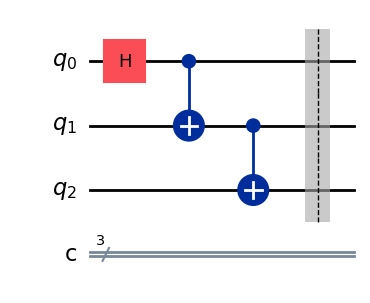

In [4]:
qc = QuantumCircuit(N_QUBITS, N_QUBITS, name="ghz_state")

for gate_name, qubits, param in GATES:
    if gate_name == "h":
        qc.h(qubits[0])
    elif gate_name == "cx":
        qc.cx(qubits[0], qubits[1])
    else:
        raise ValueError(f"Unhandled gate in GATES: {gate_name}")

qc.barrier()
qc.draw(output="mpl")

## 3. Draw the circuit and save to file

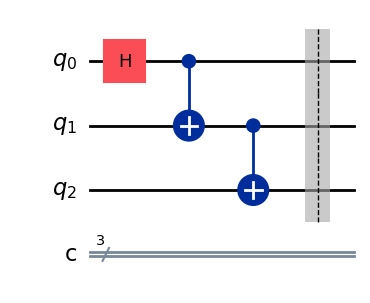

In [5]:
fig = qc.draw(output="mpl")
fig.savefig("ghz_state_qiskit_circuit.png", bbox_inches="tight")
fig

## 4. Explicit matrix representation of the key operator(s)

In [6]:
H_matrix = (1 / np.sqrt(2)) * np.array([[1, 1],
                                          [1, -1]], dtype=complex)
print("H matrix:")
print(np.round(H_matrix, 4))
print()

def cx_matrix(control, target, n_qubits):
    """CX matrix for arbitrary control/target in an n-qubit system,
    basis ordered with qubit 0 = rightmost (LSB) -- same convention as the
    Bell-state notebook, generalized to n qubits."""
    dim = 2 ** n_qubits
    M = np.zeros((dim, dim), dtype=complex)
    for idx in range(dim):
        bits = [(idx >> k) & 1 for k in range(n_qubits)]  # bits[k] = qubit k value
        if bits[control] == 1:
            bits[target] = 1 - bits[target]
        new_idx = sum(b << k for k, b in enumerate(bits))
        M[new_idx, idx] = 1
    return M

CX01 = cx_matrix(0, 1, N_QUBITS)
CX12 = cx_matrix(1, 2, N_QUBITS)
print(f"CX(control=0, target=1) matrix, {2**N_QUBITS}x{2**N_QUBITS}, basis qubit0=rightmost:")
print(np.round(CX01.real, 4))
print()
print(f"CX(control=1, target=2) matrix, {2**N_QUBITS}x{2**N_QUBITS}, basis qubit0=rightmost:")
print(np.round(CX12.real, 4))

H matrix:
[[ 0.7071+0.j  0.7071+0.j]
 [ 0.7071+0.j -0.7071+0.j]]

CX(control=0, target=1) matrix, 8x8, basis qubit0=rightmost:
[[1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]]

CX(control=1, target=2) matrix, 8x8, basis qubit0=rightmost:
[[1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]]


In [7]:
def single_qubit_op_embedded(op, qubit, n_qubits):
    """Embed a 2x2 single-qubit operator into the full n-qubit space,
    with qubit 0 = rightmost/LSB (same tensor order as Qiskit's Statevector)."""
    mats = []
    for q in reversed(range(n_qubits)):
        mats.append(op if q == qubit else np.eye(2, dtype=complex))
    full = mats[0]
    for m in mats[1:]:
        full = np.kron(full, m)
    return full

H_embedded = single_qubit_op_embedded(H_matrix, 0, N_QUBITS)
manual_full_op = CX12 @ CX01 @ H_embedded

prep_circuit = QuantumCircuit(N_QUBITS, name="prep_only")
for gate_name, qubits, param in GATES:
    if gate_name == "h":
        prep_circuit.h(qubits[0])
    elif gate_name == "cx":
        prep_circuit.cx(qubits[0], qubits[1])

full_op = Operator(prep_circuit)
print(f"Full {2**N_QUBITS}x{2**N_QUBITS} operator from Qiskit (basis qubit0=rightmost):")
print(np.round(full_op.data, 4))

assert np.allclose(full_op.data, manual_full_op, atol=1e-6), "Operator mismatch between Qiskit and manual construction!"
print()
print("Cross-check against manually constructed CX12 @ CX01 @ H_embedded: MATCH")

Full 8x8 operator from Qiskit (basis qubit0=rightmost):
[[ 0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j  0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.7071+0.j -0.7071+0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j
   0.    +0.j  0.    +0.j]
 [ 0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.7071+0.j -0.7071+0.j]
 [ 0.    +0.j  0.    +0.j  0.7071+0.j  0.7071+0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]
 [ 0.7071+0.j -0.7071+0.j  0.    +0.j  0.    +0.j  0.    +0.j  0.    +0.j
   0.    +0.j  0.    +0.j]]

Cross-check against manually constructed CX12 @ CX01 @ H_embedded: MATCH


## 5. Exact statevector (before measurement), reordered if needed, global-phase normalized

In [8]:
sv = Statevector.from_instruction(qc)
amps = sv.data.copy()

def reorder_if_needed(amps, n_qubits, needs_reversal):
    if not needs_reversal:
        return amps.copy()
    dim = 2 ** n_qubits
    reordered = np.zeros(dim, dtype=complex)
    for native_idx in range(dim):
        native_bits = format(native_idx, f"0{n_qubits}b")
        target_bits = native_bits[::-1]
        target_idx = int(target_bits, 2)
        reordered[target_idx] = amps[native_idx]
    return reordered

def normalize_global_phase(statevector_data, n_qubits):
    dim = 2 ** n_qubits
    bitstrings = [format(i, f"0{n_qubits}b") for i in range(dim)]
    order = np.argsort(bitstrings)
    for idx in order:
        amp = statevector_data[idx]
        if abs(amp) > 1e-9:
            phase = np.angle(amp)
            corrected = statevector_data * np.exp(-1j * phase)
            return corrected, bitstrings
    return statevector_data, bitstrings

amps_contract = reorder_if_needed(amps, N_QUBITS, NEEDS_REVERSAL)
amps_norm, bitstrings = normalize_global_phase(amps_contract, N_QUBITS)

exact_probs = {}
for i, bs in enumerate(bitstrings):
    exact_probs[bs] = round(abs(amps_norm[i]) ** 2, 4)

exact_probs = dict(sorted(exact_probs.items()))
print("Exact statevector amplitudes (contract order, phase-normalized):")
print(np.round(amps_norm, 4))
print()
print("Exact statevector probabilities (qubit0 = rightmost):")
print(exact_probs)

Exact statevector amplitudes (contract order, phase-normalized):
[0.7071+0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j 0.    +0.j
 0.    +0.j 0.7071+0.j]

Exact statevector probabilities (qubit0 = rightmost):
{'000': np.float64(0.5), '001': np.float64(0.0), '010': np.float64(0.0), '011': np.float64(0.0), '100': np.float64(0.0), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(0.5)}


## 6. Measurement: add measurements, run AerSimulator, plot histogram

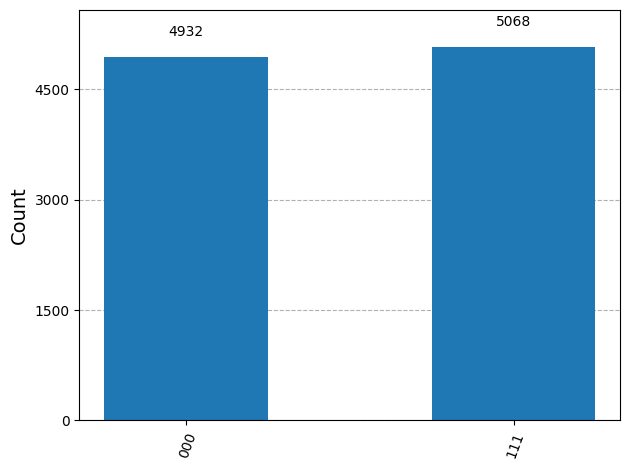

In [9]:
qc_measured = qc.copy()
qc_measured.measure(range(N_QUBITS), range(N_QUBITS))

sim = AerSimulator(seed_simulator=SEED)
job = sim.run(qc_measured, shots=SHOTS, seed_simulator=SEED)
result = job.result()
raw_counts = result.get_counts()

def reorder_counts_if_needed(counts, needs_reversal):
    if not needs_reversal:
        return dict(counts)
    out = {}
    for bs, c in counts.items():
        rbs = bs[::-1]
        out[rbs] = out.get(rbs, 0) + c
    return out

counts = reorder_counts_if_needed(raw_counts, NEEDS_REVERSAL)

fig2 = plot_histogram(counts)
fig2.savefig("ghz_state_qiskit_histogram.png", bbox_inches="tight")
fig2

In [10]:
sampled_probs = {bs: round(c / SHOTS, 4) for bs, c in counts.items()}
sampled_probs = dict(sorted(sampled_probs.items()))
print(f"Sampled probabilities ({SHOTS} shots, seed={SEED}):")
print(sampled_probs)

Sampled probabilities (10000 shots, seed=42):
{'000': 0.4932, '111': 0.5068}


## 7. Circuit resource counts

In [11]:
print(f"Depth: {qc_measured.depth()}")
print(f"Gate/operation count: {qc_measured.size()}")
print(f"Gates in shared GATES spec: {len(GATES)}  (h + 2x cx, matches circuit build)")

Depth: 4
Gate/operation count: 6
Gates in shared GATES spec: 3  (h + 2x cx, matches circuit build)


## 8. Convention notes

In [15]:
print(f"Bit ordering: calibration in Section 1 found NEEDS_REVERSAL = {NEEDS_REVERSAL}.")
print("For Qiskit, Statevector/get_counts() natively index qubit 0 as the rightmost")
print("(least-significant) bit, which already matches the qubit0=rightmost CONTRACT --")
print("so no reversal was needed, confirmed empirically rather than assumed.")
print()
print("Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring")
print("order and rotating the whole statevector so that amplitude becomes real and positive.")
print("For this primitive, both nonzero amplitudes (|000>, |111>) are real and equal by")
print("construction, so this normalization step is a no-op here.")

Bit ordering: calibration in Section 1 found NEEDS_REVERSAL = False.
For Qiskit, Statevector/get_counts() natively index qubit 0 as the rightmost
(least-significant) bit, which already matches the qubit0=rightmost CONTRACT --
so no reversal was needed, confirmed empirically rather than assumed.

Global phase: normalized by finding the first nonzero amplitude in ascending-bitstring
order and rotating the whole statevector so that amplitude becomes real and positive.
For this primitive, both nonzero amplitudes (|000>, |111>) are real and equal by
construction, so this normalization step is a no-op here.


## 9. Hand-derived expected result (independent sanity check)

Derived directly from the gate definitions, independent of the code above: H puts qubit 0 into (|0>+|1>)/sqrt(2); CX(0,1) copies that value onto qubit 1, and CX(1,2) then copies qubit 1's value onto qubit 2, so all three qubits end up equal -- (|000> + |111>) / sqrt(2). Expected probabilities: `{'000': 0.5, '111': 0.5}`, all other bitstrings 0.

In [16]:
EXPECTED_PROBS = {format(i, f"0{N_QUBITS}b"): 0.0 for i in range(2 ** N_QUBITS)}
EXPECTED_PROBS["0" * N_QUBITS] = 0.5
EXPECTED_PROBS["1" * N_QUBITS] = 0.5

max_delta_vs_hand = max(abs(exact_probs.get(k, 0) - EXPECTED_PROBS.get(k, 0))
                         for k in set(exact_probs) | set(EXPECTED_PROBS))
print("Max delta vs. hand-derived expectation:", max_delta_vs_hand)
assert max_delta_vs_hand < 1e-6, "Computed result does not match hand-derived GHZ state probabilities!"
print("Sanity check PASSED: exact_probs matches the hand-derived expectation.")

Max delta vs. hand-derived expectation: 0.0
Sanity check PASSED: exact_probs matches the hand-derived expectation.


## Final result (for diffing against the CUDA-Q version)

In [14]:
QISKIT_RESULT = exact_probs
print("QISKIT_RESULT =", QISKIT_RESULT)

QISKIT_RESULT = {'000': np.float64(0.5), '001': np.float64(0.0), '010': np.float64(0.0), '011': np.float64(0.0), '100': np.float64(0.0), '101': np.float64(0.0), '110': np.float64(0.0), '111': np.float64(0.5)}


## 10. Diff check against CUDA-Q

Paste the `CUDAQ_RESULT` dict printed at the end of the CUDA-Q notebook below, then run this cell.

In [ ]:
CUDAQ_RESULT = {'000': 0.5, '001': 0.0, '010': 0.0, '011': 0.0,
                 '100': 0.0, '101': 0.0, '110': 0.0, '111': 0.5}  # <-- paste from the CUDA-Q notebook's printed output

all_keys = sorted(set(QISKIT_RESULT) | set(CUDAQ_RESULT))
max_delta = max(abs(QISKIT_RESULT.get(k, 0) - CUDAQ_RESULT.get(k, 0)) for k in all_keys)
print("Max probability delta:", max_delta)
print("Match within tolerance:", max_delta < 1e-3)
assert max_delta < 1e-3, "Qiskit and CUDA-Q results disagree beyond tolerance!"
print("PASS: Qiskit and CUDA-Q results agree.")